<a href="https://colab.research.google.com/github/Harshitha-3-prog/Deep-learning-CCA/blob/main/1_pytorch_unet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. PyTorch – U-Net for textile defect segmentation
Runtime: **CPU** (Runtime → Change runtime type → CPU). Use the **same** runtime type as the Keras notebook. Run all cells in order. Keep the browser tab open during training.

In [7]:
# ---- Shared configuration (keep IDENTICAL in both framework notebooks) ----
import os, time, json, sys, platform
import numpy as np, psutil
SEED, BATCH, EPOCHS, LR, NCLS = 42, 8, 20, 1e-3, 5
DRIVE = "/content/drive/MyDrive/CCA2"
DATA  = f"{DRIVE}/fabric_256.npz"
from google.colab import drive
drive.mount("/content/drive")

import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
torch.manual_seed(SEED); np.random.seed(SEED)
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.is_available(), "| threads:", torch.get_num_threads())
d = np.load(DATA)
Xtr, Ytr, Xva, Yva, Xte, Yte = [d[k] for k in ["X_train","Y_train","X_val","Y_val","X_test","Y_test"]]
print(Xtr.shape, Xva.shape, Xte.shape, list(d["class_names"]))
mk = lambda X, Y, sh: DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(Y)), batch_size=BATCH, shuffle=sh)
train_loader, val_loader, test_loader = mk(Xtr,Ytr,True), mk(Xva,Yva,False), mk(Xte,Yte,False)
train_eval_loader = mk(Xtr,Ytr,False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch 2.14.1+cpu | GPU: False | threads: 1
(1685, 256, 256, 3) (364, 256, 256, 3) (358, 256, 256, 3) [np.str_('background'), np.str_('Needle Mark'), np.str_('Hole'), np.str_('Missing Yarn'), np.str_('Stains')]


In [9]:
# ---- Shared metric code (identical in both notebooks) ----
def conf_matrix(y_true, y_pred, n=NCLS):
    return np.bincount((y_true.astype(np.int64) * n + y_pred).ravel(),
                       minlength=n * n).reshape(n, n)

def summarize(conf):
    acc = np.trace(conf) / conf.sum()                 # pixel accuracy
    inter = np.diag(conf)
    union = conf.sum(0) + conf.sum(1) - inter
    iou = np.where(union > 0, inter / np.maximum(union, 1), np.nan)
    return acc, iou                                    # iou[0] = background

In [10]:
# ---- Model (this is the code to show in report Section 3.2) ----
def block(i, o):
    return nn.Sequential(nn.Conv2d(i,o,3,padding=1), nn.ReLU(),
                         nn.Conv2d(o,o,3,padding=1), nn.ReLU())
class UNet(nn.Module):
    def __init__(s, n_cls=5):
        super().__init__()
        s.e1, s.e2, s.e3 = block(3,16), block(16,32), block(32,64)
        s.pool = nn.MaxPool2d(2)
        s.up2, s.d2 = nn.ConvTranspose2d(64,32,2,stride=2), block(64,32)
        s.up1, s.d1 = nn.ConvTranspose2d(32,16,2,stride=2), block(32,16)
        s.out = nn.Conv2d(16, n_cls, 1)
    def forward(s, x):
        x1 = s.e1(x); x2 = s.e2(s.pool(x1)); x3 = s.e3(s.pool(x2))
        y = s.d2(torch.cat([s.up2(x3), x2], 1))
        y = s.d1(torch.cat([s.up1(y), x1], 1))
        return s.out(y)                      # logits (N,5,256,256)
model = UNet(NCLS); loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=LR)
n_params = sum(p.numel() for p in model.parameters()); print("Parameters:", n_params)

Parameters: 117109


In [4]:
prep = lambda xb, yb: (xb.permute(0,3,1,2).float() / 255, yb.long())

def evaluate(loader):
    model.eval(); loss_sum = 0.0; n = 0; conf = np.zeros((NCLS, NCLS), dtype=np.int64)
    with torch.no_grad():
        for xb, yb in loader:
            x, y = prep(xb, yb); out = model(x)
            loss_sum += loss_fn(out, y).item() * len(x); n += len(x)
            conf += conf_matrix(y.numpy(), out.argmax(1).numpy())
    return loss_sum / n, conf

proc = psutil.Process()
H = {"train_loss": [], "val_loss": [], "epoch_time": [], "rss_mb": []}
t_all = time.time()
for ep in range(EPOCHS):
    model.train(); t0 = time.time(); run = 0.0; n = 0
    for xb, yb in train_loader:
        x, y = prep(xb, yb)
        opt.zero_grad(); loss = loss_fn(model(x), y)
        loss.backward(); opt.step()
        run += loss.item() * len(x); n += len(x)
    vl, _ = evaluate(val_loader)
    H["train_loss"].append(run / n); H["val_loss"].append(vl)
    H["epoch_time"].append(time.time() - t0); H["rss_mb"].append(proc.memory_info().rss / 1e6)
    print(f"Epoch {ep+1}/{EPOCHS} - loss: {run/n:.4f} - val_loss: {vl:.4f} - time: {H['epoch_time'][-1]:.1f}s", flush=True)
total_time = time.time() - t_all

Epoch 1/20 - loss: 0.2245 - val_loss: 0.1305 - time: 381.2s
Epoch 2/20 - loss: 0.1245 - val_loss: 0.1306 - time: 377.2s
Epoch 3/20 - loss: 0.1226 - val_loss: 0.1249 - time: 382.1s
Epoch 4/20 - loss: 0.1220 - val_loss: 0.1248 - time: 382.6s
Epoch 5/20 - loss: 0.1216 - val_loss: 0.1251 - time: 377.6s
Epoch 6/20 - loss: 0.1215 - val_loss: 0.1266 - time: 378.6s
Epoch 7/20 - loss: 0.1211 - val_loss: 0.1237 - time: 377.7s
Epoch 8/20 - loss: 0.1215 - val_loss: 0.1251 - time: 379.9s
Epoch 9/20 - loss: 0.1210 - val_loss: 0.1243 - time: 379.3s
Epoch 10/20 - loss: 0.1212 - val_loss: 0.1238 - time: 377.2s
Epoch 11/20 - loss: 0.1199 - val_loss: 0.1232 - time: 379.2s
Epoch 12/20 - loss: 0.1202 - val_loss: 0.1217 - time: 381.6s
Epoch 13/20 - loss: 0.1194 - val_loss: 0.1246 - time: 382.2s
Epoch 14/20 - loss: 0.1191 - val_loss: 0.1216 - time: 381.8s
Epoch 15/20 - loss: 0.1183 - val_loss: 0.1218 - time: 380.1s
Epoch 16/20 - loss: 0.1178 - val_loss: 0.1190 - time: 381.7s
Epoch 17/20 - loss: 0.1167 - val_

In [5]:
# ---- Final evaluation ----
tr_loss_eval, c_tr = evaluate(train_eval_loader); va_loss, c_va = evaluate(val_loader); te_loss, c_te = evaluate(test_loader)
(acc_tr, _), (acc_va, _), (acc_te, iou_te) = summarize(c_tr), summarize(c_va), summarize(c_te)
# inference time: one image at a time, after one warm-up call
xs = torch.from_numpy(Xte[:50]).permute(0,3,1,2).float() / 255
model.eval()
with torch.no_grad():
    model(xs[:1]); t = time.time()
    for i in range(50): model(xs[i:i+1])
inf_ms = (time.time() - t) / 50 * 1000

R = {"framework": "PyTorch " + torch.__version__, "epochs": EPOCHS, "params": n_params,
     "train_acc": acc_tr, "val_acc": acc_va, "test_acc": acc_te,
     "final_train_loss": H["train_loss"][-1], "final_val_loss": H["val_loss"][-1], "test_loss": te_loss,
     "test_mIoU_defects": float(np.nanmean(iou_te[1:])), "test_IoU_per_class": [None if np.isnan(v) else float(v) for v in iou_te],
     "total_train_time_s": total_time, "mean_epoch_time_s": float(np.mean(H["epoch_time"])),
     "inference_ms_per_image": inf_ms, "peak_rss_mb": max(H["rss_mb"]), "history": H}
json.dump(R, open(f"{DRIVE}/results_pytorch.json", "w"), indent=1)
print("=== COPY THIS BLOCK ===")
for k, v in R.items():
    if k != "history": print(f"{k}: {v}")

=== COPY THIS BLOCK ===
framework: PyTorch 2.14.1+cpu
epochs: 20
params: 117109
train_acc: 0.9796379293107845
val_acc: 0.9794833005129636
test_acc: 0.9815854972967223
final_train_loss: 0.11430639467182782
final_val_loss: 0.11559997081429094
test_loss: 0.10838191993742682
test_mIoU_defects: 0.0
test_IoU_per_class: [0.9815854972967223, 0.0, 0.0, 0.0, 0.0]
total_train_time_s: 7600.515588283539
mean_epoch_time_s: 380.0240548849106
inference_ms_per_image: 52.87564277648926
peak_rss_mb: 1297.686528


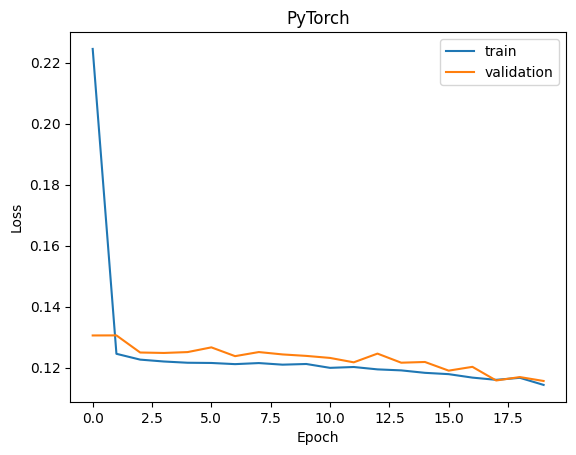

In [6]:
import matplotlib.pyplot as plt
plt.plot(H["train_loss"], label="train"); plt.plot(H["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("PyTorch"); plt.legend()
plt.savefig(f"{DRIVE}/pytorch_curves.png", dpi=150, bbox_inches="tight"); plt.show()